# Hafta 01: Bilgisayar Ağlarına Giriş — Ağ Mimarisi ve Bir Emojinin Yolculuğu

> **Ders Kitabı Referansı:** Computer Networking: A Top-Down Approach (J.F. Kurose, K.W. Ross — Bölüm 1)

---

## 1. Ağları Neden Öğreniyoruz? (Yazılım ve Güvenlik Perspektifi)

Modern yazılım dünyasında bulut bilişim, mikroservisler, dağıtık sistemler, IoT ve 5G teknolojilerinin tamamı ağ altyapısı üzerinde yükselir. Ancak yazılım mühendisleri için bilgisayar ağlarını bilmenin en kritik gerekçesi **Siber Güvenlik / Bilgi Güvenliği** ve **Yazılımsal Soyutlamayı (Abstraction) Kırmaktır**:

* **Soyutlamayı (Abstraction) Kırmak:** Bir yazılımcı çoğunlukla `fetch()`, `HttpClient` veya `socket.send()` çağrısı yaparak veriyi gönderir ve işin bittiğini varsayar. Oysa arka planda işletim sistemi soket tamponları, hat gecikmeleri (RTT), paket kayıpları ve yönlendirme kararları çalışır. Ağın çalışma mantığını bilmeyen bir geliştirici performanslı ve ölçeklenebilir backend mimarileri kuramaz.
* **Siber Güvenliğin Temeli Ağdır:** Güvenli yazılım geliştirmek; paket başlıklarını, açık portları, IP rotalarını, taşıma şifrelemesini (TLS) ve yerel ağ açıklarını (ARP Zehirlenmesi vb.) kod seviyesinde kavramaktan geçer.

---

### 1.1. Dönemin Büyük Resmi: Kurose & Ross Katman Haritası

Bu ders boyunca interneti, kullanıcının konuştuğu en üst katmandan kabloya doğru (*Top-Down*) inceleyeceğiz:

| Katman | Temel Sorumluluk ve Odak | İncelenecek Protokoller | İlgili Cihaz / Seviye |
| :--- | :--- | :--- | :--- |
| **Bölüm 2: Uygulama (Application)** | Ağ uygulamalarının ortak dili, mesaj formatları. | HTTP/HTTPS, DNS, SMTP, FTP, DHCP | Uç Sistemler (Tarayıcı, Sunucu) |
| **Bölüm 3: Taşıma (Transport)** | Süreçler arası güvenli/hızlı iletim, port yönetimi. | TCP, UDP, TLS | İşletim Sistemi (OS / Kernel) |
| **Bölüm 4: Ağ (Network)** | Paketlerin küresel ağlar arasında yönlendirilmesi (*Routing*). | IP (IPv4/IPv6), ICMP, RIP, OSPF | Yönlendiriciler (Router) |
| **Bölüm 5: Veri Bağı (Link)** | Aynı yerel ağdaki komşu cihazlar arası çerçeve iletimi. | Ethernet, Wi-Fi, ARP | Ağ Anahtarları (Switch), NIC |
| **Bölüm 6: Fiziksel (Physical)** | Bitlerin elektrik/ışık/radyo dalgasına dönüşümü. | Voltaj, Fiber Işığı, RF Dalgaları | Kablolar, Antenler |

> **SORU: Fiziksel Katman Neden Bu Derste Detaylı İşlenmez?**  
> **CEVAP:** Fiziksel katman; bakır kablodaki gerilim seviyeleri, fiber optik dalga boyları veya elektromanyetik modülasyon gibi tamamen Elektrik-Elektronik ve Haberleşme Mühendisliği disiplinine giren donanımsal konuları kapsar. Bir Yazılım Mühendisi için kritik olan; verinin bitlere dönüştüğü andan itibaren işletim sistemi çekirdeğinde, soketlerde ve protokol yazılımlarında nasıl yönetildiğidir.

---

### 1.2. Temel Ağ Bileşenleri ve Paket Anahtarlama (Packet Switching)

1. **Uç Sistemler (Hosts / End Systems):** Ağın sınırında (*Edge*) çalışan istemciler (PC, akıllı telefon, IoT sensörü) ve sunuculardır. Ağ uygulamaları **yalnızca uç sistemlerde çalışır**.
2. **Ağ Çekirdeği (Network Core):** Switch ve Router gibi ara bağlantı cihazlarıdır. Görevleri uygulama çalıştırmak değil, veriyi kaynaktan hedefe iletmektir.
3. **Paket Anahtarlama Mantığı (Kargo Benzetmesi):** Ağda büyük bir dosya tek bir blok halinde kabloya sürülmez. Büyük bir yükün demonte edilip standart koli kutularına bölünmesi ve üzerlerine adres etiketi (**Header / Başlık**) yapıştırılarak farklı kargo araçlarıyla gönderilmesi gibi; veriler de standart paketlere bölünür. Her paket ağda bağımsız hareket eder ve hedefte sıra numarasına göre birleştirilir.

---

### 1.3. Protokol Nedir? (Yazılım Perspektifi)

Bir ağ protokolü; iki veya daha fazla taraf arasında veri alışverişinin kurallarını tanımlayan standart yazılım sözleşmesidir:

$$\text{Protokol} = \text{Mesaj Biçimi (Syntax)} + \text{Alanların Anlamı (Semantics)} + \text{Mesaj Sırası ve Eylemler (Timing & Actions)}$$

* **İnsan İletişimi:** Karşılaşınca *"Merhaba"* dersiniz, yanıt *"Merhaba"* gelir; *"Saat kaç?"* dersiniz, *"14:30"* cevabı döner.
* **Ağ İletişimi:** İstemci sunucuya TCP bağlantı isteği atar, sunucu onaylar, istemci `GET /index.html HTTP/1.1` metnini iletir, sunucu `200 OK` koduyla web sayfasını teslim eder.

---
## 2. Mimari Görselleştirme: Kapsülleme Zinciri (Bayt Treni ve Vagonlar)

Bir sohbet uygulamasından gönderilen tek bir `😀` emojisi, kabloya doğru inerken her katmanda önüne yeni bir başlık eklenerek tek parça bir **bayt treni** haline gelir. Karşı tarafta ise her katman kendi vagonunu okuyup soyar (*Decapsulation*).

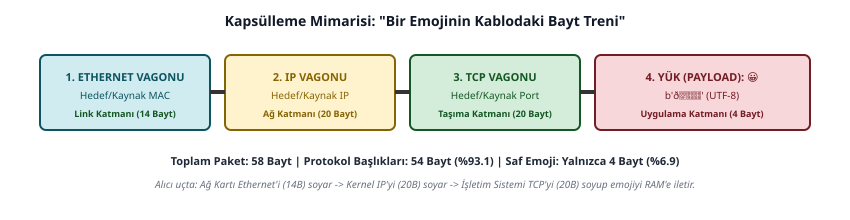

In [1]:
from IPython.display import SVG, display

svg_tren = """
<svg width="850" height="220" viewBox="0 0 850 220" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
  <text x="425" y="26" text-anchor="middle" font-size="14" font-weight="bold" fill="#111827">
    Kapsülleme Mimarisi: "Bir Emojinin Kablodaki Bayt Treni"
  </text>
  
  <!-- 1. VAGON: ETHERNET BAŞLIĞI -->
  <g transform="translate(40, 55)">
    <rect width="170" height="75" rx="6" fill="#d1ecf1" stroke="#0c5460" stroke-width="2"/>
    <text x="85" y="26" text-anchor="middle" font-size="11" font-weight="bold" fill="#0c5460">1. ETHERNET VAGONU</text>
    <text x="85" y="44" text-anchor="middle" font-size="10" fill="#0c5460">Hedef/Kaynak MAC</text>
    <text x="85" y="62" text-anchor="middle" font-size="9" font-weight="bold" fill="#155724">Link Katmanı (14 Bayt)</text>
  </g>

  <!-- 2. VAGON: IP BAŞLIĞI -->
  <g transform="translate(225, 55)">
    <rect width="170" height="75" rx="6" fill="#fff3cd" stroke="#856404" stroke-width="2"/>
    <text x="85" y="26" text-anchor="middle" font-size="11" font-weight="bold" fill="#856404">2. IP VAGONU</text>
    <text x="85" y="44" text-anchor="middle" font-size="10" fill="#856404">Hedef/Kaynak IP</text>
    <text x="85" y="62" text-anchor="middle" font-size="9" font-weight="bold" fill="#856404">Ağ Katmanı (20 Bayt)</text>
  </g>

  <!-- 3. VAGON: TCP BAŞLIĞI -->
  <g transform="translate(410, 55)">
    <rect width="170" height="75" rx="6" fill="#d4edda" stroke="#155724" stroke-width="2"/>
    <text x="85" y="26" text-anchor="middle" font-size="11" font-weight="bold" fill="#155724">3. TCP VAGONU</text>
    <text x="85" y="44" text-anchor="middle" font-size="10" fill="#155724">Hedef/Kaynak Port</text>
    <text x="85" y="62" text-anchor="middle" font-size="9" font-weight="bold" fill="#155724">Taşıma Katmanı (20 Bayt)</text>
  </g>

  <!-- 4. VAGON: SAF YÜK (PAYLOAD) -->
  <g transform="translate(595, 55)">
    <rect width="215" height="75" rx="6" fill="#f8d7da" stroke="#721c24" stroke-width="2"/>
    <text x="107" y="26" text-anchor="middle" font-size="11" font-weight="bold" fill="#721c24">4. YÜK (PAYLOAD): 😀</text>
    <text x="107" y="44" text-anchor="middle" font-size="10" fill="#721c24">b'\xf0\x9f\x98\x80' (UTF-8)</text>
    <text x="107" y="62" text-anchor="middle" font-size="9" font-weight="bold" fill="#721c24">Uygulama Katmanı (4 Bayt)</text>
  </g>

  <!-- Bağlantı Zincirleri -->
  <line x1="210" y1="92" x2="225" y2="92" stroke="#333333" stroke-width="4"/>
  <line x1="395" y1="92" x2="410" y2="92" stroke="#333333" stroke-width="4"/>
  <line x1="580" y1="92" x2="595" y2="92" stroke="#333333" stroke-width="4"/>

  <!-- Alt Açıklama -->
  <text x="425" y="165" text-anchor="middle" font-size="11" font-weight="bold" fill="#1f2937">
    Toplam Paket: 58 Bayt | Protokol Başlıkları: 54 Bayt (%93.1) | Saf Emoji: Yalnızca 4 Bayt (%6.9)
  </text>
  <text x="425" y="188" text-anchor="middle" font-size="10" fill="#6b7280" font-style="italic">
    Alıcı uçta: Ağ Kartı Ethernet'i (14B) soyar -&gt; Kernel IP'yi (20B) soyar -&gt; İşletim Sistemi TCP'yi (20B) soyup emojiyi RAM'e iletir.
  </text>
</svg>
"""
display(SVG(svg_tren))

---
## 3. Üç Seviyeli Adresleme ve Temel Formül

Bir mesajlaşma uygulamasından gönderilen tek bir `😀` emojisi fiziksel kabloya veya Wi-Fi antenine şu denklemle iner:

$$\text{Kablodaki Bit Treni} = \underbrace{[\text{Hedef/Kaynak MAC}]}_{\text{Link: Ethernet (14B)}} + \underbrace{[\text{Hedef/Kaynak IP}]}_{\text{Network: IP (20B)}} + \underbrace{[\text{Hedef/Kaynak Port}]}_{\text{Transport: TCP (20B)}} + \underbrace{\text{"😀"}}_{\text{Payload: UTF-8 (4B)}}$$

Alıcı makinenin donanımı ve işletim sistemi ise bu sırayı tersten işleterek başlıkları sırayla söker (**Decapsulation**):
1. **Ağ Kartı (NIC - Donanım Seviyesi):** Kablodan gelen ilk 14 baytı okur. Hedef MAC kendi adresiyle eşleşmiyorsa paketi anında çöpe atar (**DROP**). CPU'nun bundan haberi bile olmaz.
2. **İşletim Sistemi Çekirdeği (Kernel - IP Seviyesi):** Donanımı geçen bayt treninin ilk 20 baytına bakar. Hedef IP makineye aitse başlığı soyar ve veriyi Taşıma Katmanına aktarır.
3. **Uygulama Belleği (RAM - Port Seviyesi):** Kalan baytların ilk 2 baytındaki Hedef Port numarasını okur (Örn: Port 8080). İşletim sistemi RAM tablosuna bakar: *"Port 8080'i hangi çalışan uygulama (Process ID) dinliyor?"* Port başlığını da silerek saf emojiyi o programın bellek kuyruğuna teslim eder.

---
## 4. Deney 1: Emojiyi Scapy ile Paketleme ve .pcap (Wireshark) Üretimi

### 4.1. Deneyin Amacı
Tek bir UTF-8 emojiyi (`😀`) saf veri yükü (Payload) olarak tanımlamak; Python `scapy` kütüphanesi ile Link (Ethernet), Ağ (IP) ve Taşıma (TCP) başlıklarını katman katman birbirine bağlayarak (*Encapsulation*) endüstri standardı bir `.pcap` (Wireshark) dosyası olarak diske kaydetmektir.

In [2]:
from scapy.all import Ether, IP, TCP, Raw, wrpcap

# 1. Uygulama Verisi (Payload): UTF-8 kodlu tek bir emoji
emoji_data = "😀".encode("utf-8")

# 2. Katmanları Yukarıdan Aşağıya İnşa Edelim (Encapsulation)
# Scapy'de '/' operatörü protokol katmanlarını birbirine bağlar.
paket = (
    Ether(src="AA:BB:CC:DD:EE:01", dst="FF:EE:DD:CC:BB:02") /
    IP(src="192.168.1.100", dst="10.0.0.1") /
    TCP(sport=54321, dport=8080, flags="PA") /
    Raw(load=emoji_data)
)

# 3. Paketi diske .pcap formatında yazalım
wrpcap("emoji_yolculugu.pcap", paket)

print("[+] Paket başarıyla oluşturuldu ve 'emoji_yolculugu.pcap' dosyasına kaydedildi.")
print(f"[+] Paketin Toplam Boyutu  : {len(paket)} bayt")
print(f"[+] Saf Emoji Veri Boyutu : {len(emoji_data)} bayt")
print(f"[+] Protokol Ek Yükü      : {len(paket) - len(emoji_data)} bayt (Ethernet + IP + TCP Başlıkları)")

C:\WINDOWS\system32\netlab\Lib\site-packages\scapy\layers\tls\crypto\groups.py:25: CryptographyDeprecationWarning: Diffie-Hellman over finite fields (FFDH) is deprecated and support will be removed in a future release. Use a more modern key exchange algorithm.
  from cryptography.hazmat.primitives.asymmetric.dh import DHParameterNumbers


[+] Paket başarıyla oluşturuldu ve 'emoji_yolculugu.pcap' dosyasına kaydedildi.
[+] Paketin Toplam Boyutu  : 58 bayt
[+] Saf Emoji Veri Boyutu : 4 bayt
[+] Protokol Ek Yükü      : 54 bayt (Ethernet + IP + TCP Başlıkları)


---
### Ek Not: `libpcap` Uyarısı, `.pcap` Dosya Formatı ve Çözümü

Laboratuvar kodunu çalıştırdığınızda konsola düşebilen şu uyarı mesajı bir kod hatası değildir:
> `WARNING: No libpcap provider available ! pcap won't be used`

#### 1. Uyarının Nedeni: Canlı Ağ Trafiğini Dinleme Kısıtı
* **Normal Soket Erişimi:** Standart bir program işletim sistemine yalnızca kendisine tahsis edilen port üzerinden gelen paketleri okuma talebinde bulunur.
* **Ham Paket Yakalama (Sniffing):** Ağ kartından geçen tüm ham baytları dinlemek veya doğrudan ağ kartına ham çerçeve basmak işletim sistemi çekirdeğinde özel sürücüler gerektirir (Linux'ta `libpcap`, Windows'ta `Npcap`).
* **Laboratuvardaki Durum:** Biz ağ kartından canlı paket dinlemiyoruz; saf Python nesneleriyle paket inşa edip (`wrpcap`) dosyadan okuyoruz (`rdpcap`). Bu dosya işlemleri saf Python ile yapıldığından donanım sürücüsüne ihtiyaç duymaz ve kod eksiksiz çalışır.

#### 2. `.pcap` Dosyası Nedir ve Nasıl İncelenir?
* **Tanım:** `.pcap` (*Packet Capture*), ağ kartından geçen veya simüle edilen ham ağ paketlerinin bayt bayt diske kaydedildiği evrensel ikili (binary) dosya formatıdır.
* **İnceleme:** Ürettiğimiz `emoji_yolculugu.pcap` dosyasını ister bir sonraki deneyde Python ile ayrıştırabilir, isterseniz ücretsiz **Wireshark** programında çift tıklayarak renkli protokol blokları halinde görsel olarak inceleyebilirsiniz.

---
## 5. Deney 2: Python ile Yazılımsal Wireshark (Paket Ayrıştırma / Decapsulation)

### 5.1. Deneyin Amacı
Diske kaydedilen `.pcap` dosyasını geri okuyarak, tıpkı alıcı makinenin ağ kartı ve işletim sistemi çekirdeği gibi katman başlıklarını dıştan içe doğru (`Ether -> IP -> TCP -> Raw`) bayt bayt ayrıştırmak ve saf emojiyi kurtarmaktır.

In [3]:
from scapy.all import rdpcap, Ether, IP, TCP, Raw

# 1. Diskteki paketi okuyalım
paketler = rdpcap("emoji_yolculugu.pcap")
p = paketler[0]

print("=" * 65)
print("PYTHON İLE KATMAN AYRIŞTIRMA ANALİZİ (DECAPSULATION)")
print("=" * 65)

# Katman 1: Link Katmanı (Ethernet Çerçevesi)
if p.haslayer(Ether):
    eth = p[Ether]
    print(f"[LINK KATMANI - MAC]       Kaynak: {eth.src} -> Hedef: {eth.dst}")

# Katman 2: Ağ Katmanı (IP Paketi)
if p.haslayer(IP):
    ip = p[IP]
    print(f"[AĞ KATMANI - IP]          Kaynak: {ip.src} -> Hedef: {ip.dst} | TTL: {ip.ttl}")

# Katman 3: Taşıma Katmanı (TCP Segmenti)
if p.haslayer(TCP):
    tcp = p[TCP]
    print(f"[TAŞIMA KATMANI - PORT]    Kaynak: {tcp.sport} -> Hedef: {tcp.dport} | Bayraklar: {tcp.flags}")

# Katman 4: Uygulama Katmanı (Yük / Payload)
if p.haslayer(Raw):
    raw = p[Raw].load
    print(f"[UYGULAMA - HAM BAYTLAR]   {raw}")
    print(f"[UYGULAMA - ÇÖZÜLEN VERİ]  {raw.decode('utf-8')}")

print("=" * 65)

PYTHON İLE KATMAN AYRIŞTIRMA ANALİZİ (DECAPSULATION)
[LINK KATMANI - MAC]       Kaynak: aa:bb:cc:dd:ee:01 -> Hedef: ff:ee:dd:cc:bb:02
[AĞ KATMANI - IP]          Kaynak: 192.168.1.100 -> Hedef: 10.0.0.1 | TTL: 64
[TAŞIMA KATMANI - PORT]    Kaynak: 54321 -> Hedef: 8080 | Bayraklar: PA
[UYGULAMA - HAM BAYTLAR]   b'\xf0\x9f\x98\x80'
[UYGULAMA - ÇÖZÜLEN VERİ]  😀


---
## 6. Deney Çıktılarının Mühendislik Yorumu

1. **Protokol Ek Yükü (Protocol Overhead):**
   * Ekrana basılan sonuçta yalnızca **4 baytlık** bir emoji göndermek için hatta **58 baytlık** paket bırakıldığı görülür.
   * Toplam paketin 54 baytı yalnızca başlık bilgisine (Ethernet: 14B + IP: 20B + TCP: 20B) harcanmıştır.
   * **Yazılım Mühendisliği Çıkarımı:** Dağıtık mimarilerde bayt bayt sürekli istek atmak iletim verimliliğini düşürür. Veriler biriktirilmeli (*Batching / Buffering*) ve tek seferde iletilmelidir.

2. **Paket Kapsülleme (Encapsulation) Zinciri:**
   * Scapy kodundaki `/` operatörü, katmanların birbirinin içine nasıl gömüldüğünü modeller.
   * Alıcı uç ise `haslayer()` mantığıyla dıştan içe doğru başlıkları soyup en son saf emojiyi işletim sistemi belleğine bırakır.

---
## 7. Laboratuvar Uygulaması: IoT Telemetri Paketinin Katmanlı İnşası ve Başlık Analizi

### 7.1. Uygulamanın Amacı
IoT (Nesnelerin İnterneti) cihazları kısıtlı işlemci gücüne, kısıtlı belleğe ve çoğunlukla pille çalışan dar bantlı ağ bağlantılarına sahiptir. Bu uygulamada amaç; hafifliği nedeniyle IoT dünyasında tercih edilen **UDP protokolü** üzerinden bir sensör verisini (`Payload`) Scapy ile katman katman paketlemek, toplam paket boyutunu ölçmek ve TCP/IP protokol başlıklarının ağa bindirdiği ek yükü somut verilerle analiz etmektir.

---

### 7.2. Yönerge
1. `TEMP:24.5C` şeklindeki ham sensör metnini UTF-8 bayt dizisine (`bytes`) dönüştürün.
2. Scapy kütüphanesinin `/` operatörünü kullanarak aşağıdaki katman hiyerarşisini oluşturun:
   * **Link Katmanı (`Ether`):** Kaynak MAC: `11:22:33:44:55:66`, Hedef MAC: `AA:BB:CC:DD:EE:FF`
   * **Ağ Katmanı (`IP`):** Kaynak IP: `192.168.1.50`, Hedef IP: `192.168.1.1`
   * **Taşıma Katmanı (`UDP`):** Kaynak Port: `45000`, Hedef Port: `9999`
   * **Uygulama Yükü (`Raw`):** Dönüştürdüğünüz bayt verisi.
3. Python `len()` fonksiyonu ile saf veri yükünün, toplam paketin ve aradaki farkın (protokol ek yükü) bayt boyutlarını hesaplayarak ekrana tablo formatında yazdırın.

In [4]:
# ==============================================================================
# UYGULAMA: IoT Sıcaklık Sensörü UDP Paket Üretimi ve Başlık Analizi
# ==============================================================================
from scapy.all import Ether, IP, UDP, Raw

def create_and_analyze_iot_packet(sensor_message: str):
    # 1. Adım: Veriyi ham baytlara dönüştür (Payload)
    payload_data = sensor_message.encode("utf-8")
    payload_len = len(payload_data)
    
    # 2. Adım: Kurose & Ross katman modeline göre paketi inşa et
    # Link (Ether) -> Network (IP) -> Transport (UDP) -> Application (Raw)
    iot_packet = (
        Ether(src="11:22:33:44:55:66", dst="AA:BB:CC:DD:EE:FF") /
        IP(src="192.168.1.50", dst="192.168.1.1") /
        UDP(sport=45000, dport=9999) /
        Raw(load=payload_data)
    )
    
    # 3. Adım: Boyut hesaplamaları
    total_len = len(iot_packet)
    overhead = total_len - payload_len
    overhead_percentage = (overhead / total_len) * 100
    
    # 4. Adım: Sonuçları ekrana formatlı şekilde bas
    print("=" * 65)
    print("IoT TELEMETRİ PAKETİ PROTOKOL BAŞLIK ANALİZİ")
    print("=" * 65)
    print(f"{'Bileşen':<25} | {'Boyut (Bayt)':<15} | {'Açıklama'}")
    print("-" * 65)
    print(f"{'Saf Veri (Payload)':<25} | {payload_len:<15} | '{sensor_message}'")
    print(f"{'Ethernet Başlığı':<25} | {14:<15} | Kaynak/Hedef MAC + EtherType")
    print(f"{'IPv4 Başlığı':<25} | {20:<15} | Kaynak/Hedef IP + TTL vb.")
    print(f"{'UDP Başlığı':<25} | {8:<15} | Kaynak/Hedef Port + Uzunluk + Checksum")
    print("-" * 65)
    print(f"{'TOPLAM PAKET BOYUTU':<25} | {total_len:<15} | Kabloya/Havaya basılan veri")
    print(f"{'PROTOKOL EK YÜKÜ (OVERHEAD)':<25} | {overhead:<15} | Sadece başlıkların kapladığı alan")
    print(f"{'BAŞLIK ORANI (%)':<25} | %{overhead_percentage:<14.1f} | Toplam hattın protokole ayrılan payı")
    print("=" * 65)

# Fonksiyonu çalıştıralım
create_and_analyze_iot_packet("TEMP:24.5C")

IoT TELEMETRİ PAKETİ PROTOKOL BAŞLIK ANALİZİ
Bileşen                   | Boyut (Bayt)    | Açıklama
-----------------------------------------------------------------
Saf Veri (Payload)        | 10              | 'TEMP:24.5C'
Ethernet Başlığı          | 14              | Kaynak/Hedef MAC + EtherType
IPv4 Başlığı              | 20              | Kaynak/Hedef IP + TTL vb.
UDP Başlığı               | 8               | Kaynak/Hedef Port + Uzunluk + Checksum
-----------------------------------------------------------------
TOPLAM PAKET BOYUTU       | 52              | Kabloya/Havaya basılan veri
PROTOKOL EK YÜKÜ (OVERHEAD) | 42              | Sadece başlıkların kapladığı alan
BAŞLIK ORANI (%)          | %80.8           | Toplam hattın protokole ayrılan payı


---
### 7.3. Çıktının Mühendislik Yorumu

```text
=================================================================
IoT TELEMETRİ PAKETİ PROTOKOL BAŞLIK ANALİZİ
=================================================================
Bileşen                   | Boyut (Bayt)    | Açıklama
-----------------------------------------------------------------
Saf Veri (Payload)        | 10              | 'TEMP:24.5C'
Ethernet Başlığı          | 14              | Kaynak/Hedef MAC + EtherType
IPv4 Başlığı              | 20              | Kaynak/Hedef IP + TTL vb.
UDP Başlığı               | 8               | Kaynak/Hedef Port + Uzunluk + Checksum
-----------------------------------------------------------------
TOPLAM PAKET BOYUTU       | 52              | Kabloya/Havaya basılan veri
PROTOKOL EK YÜKÜ (OVERHEAD) | 42              | Sadece başlıkların kapladığı alan
BAŞLIK ORANI (%)          | %80.8           | Toplam hattın protokole ayrılan payı
=================================================================
```

#### Mühendislik Yorumu:
1. **UDP ve TCP Başlık Farkı:** TCP başlığı **20 bayt** yer tutarken, bu uygulamada UDP başlığının yalnızca **8 bayt** olduğu doğrulanmıştır. Her saniye hafif telemetri verisi fırlatan IoT cihazlarında UDP seçimi, tek başına paket başına 12 baytlık hat ve pil tasarrufu sağlar.
2. **Aşırı Protokol Ek Yükü Sorunu (%80.8):** Taşınan sıcaklık bilgisi yalnızca **10 bayttır**. Ancak bu veriyi hedefe ulaştırmak için toplam **42 baytlık** adresleme başlığı eklenmiştir. Kablodan geçen verinin **%80.8'i sırf adresleme etiketidir**.
3. **Yazılım Geliştirici İçin Çıkarım:** Her bir ölçümü tek tek ayrı paketler halinde göndermek yerine; örneğin 60 saniyelik veriyi cihaz belleğinde toplayıp (*Batching*) tek bir UDP paketiyle göndermek hat verimliliğini %20'lerden %90'ların üzerine çıkarır. Yazılımdaki tamponlama (*buffering*) mantığının temel sebebi bu fiziksel başlık yüküdür.